# 10주차: 분석 대상 선정과 Table 1
- 자료: 국민건강영양조사 2024년 (`HN24_ALL.sav`)
- 노출(E): 스트레스 인지율 (`mh_stress`, 1 = 고위험군 = 노출군 / 0 = 저위험군 = 비교군)
- 결과(O): 하루 평균 수면시간 (`BP16_11` ~ `BP16_24`로 계산)
- 구성: 1) 설정과 자료 읽기 → 2) 변수 만들기와 원 코드 빈도표 → 3) 분석 대상 표시변수와 단계별 인원(B-1) → 4) 설계 기반 Table 1(B-2) → 5) 비가중 표와 차이(B-3)
- 처음부터 끝까지 `런타임 → 세션 다시 시작 및 모두 실행`으로 돌아가야 합니다.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PATH = '/content/drive/MyDrive/hdac_data/HN24_ALL.sav'   # 9주차와 같은 자료
W = 'wt_itvex'        # 가중치: 9주차 정의표에서 정한 값과 같은지 확인할 것
STRATA = 'kstrata'    # 층
PSU = 'psu'           # 집락


## 1. Drive 연결과 정의표 변수만 읽기


In [2]:
from google.colab import drive
drive.mount('/content/drive')
!pip -q install pyreadstat
import pyreadstat

if not os.path.exists(PATH):
    for r, _, fs in os.walk('/content/drive'):
        if 'HN24_ALL.sav' in fs:
            PATH = os.path.join(r, 'HN24_ALL.sav'); break

_, meta = pyreadstat.read_sav(PATH, metadataonly=True)
labels = meta.column_names_to_labels
all_cols = meta.column_names

# 정의표의 Sm_present(현재 흡연율): 자료의 실제 변수 이름 찾기
sm_candidates = [c for c in all_cols if c.lower().startswith('sm_pres')]
print('Sm_present 후보:', [(c, labels[c]) for c in sm_candidates])
V_SMOKE = sm_candidates[0] if sm_candidates else 'BS3_1'
if not sm_candidates:
    print('경고: sm_pres로 시작하는 변수가 없어 BS3_1로 대체했습니다. 이용지침서 142쪽으로 정의를 확인하세요.')

TCOLS = ['BP16_11','BP16_12','BP16_13','BP16_14','BP16_21','BP16_22','BP16_23','BP16_24']
PHQ = [f'BP_PHQ_{i}' for i in range(1, 10)]
GAD = [f'BP_GAD_{i}' for i in range(1, 8)]
need = ['kstrata','psu',W,'age','sex','marri_1','incm','edu','EC1_1','EC_wht_23','EC_wht_5',
        'DI1_dg',V_SMOKE,'BD1_11','pa_aerobic','BP1','mh_stress','mh_PHQ_S','mh_GAD_S'] + TCOLS + PHQ + GAD
need = list(dict.fromkeys(need))
df, _ = pyreadstat.read_sav(PATH, usecols=need)
print(df.shape)   # (6997, 열 수)


Mounted at /content/drive
Sm_present 후보: [('sm_presnt', '현재흡연율')]
(6997, 43)


## 2. 변수 정의표대로 변수 만들기 (원 코드 빈도표로 확인)


In [3]:
# 2-1. 원 코드 빈도표 (비해당·무응답 코드를 눈으로 확인)
for v in ['BP1','mh_stress','sex','marri_1','incm','edu','EC1_1','EC_wht_5','DI1_dg',V_SMOKE,'BD1_11','pa_aerobic']:
    print(f'\n[{v}] {labels.get(v)}')
    print(df[v].value_counts(dropna=False).sort_index().to_string())

# 2-2. 노출 확인: mh_stress = 1 은 BP1 이 1, 2 (대단히/많이 느낀다)인 경우인지
print()
print(pd.crosstab(df['BP1'], df['mh_stress'], dropna=False))



[BP1] 평소 스트레스 인지 정도
BP1
1.0     297
2.0    1216
3.0    3409
4.0    1286
8.0     561
9.0     219
NaN       9

[mh_stress] 스트레스 인지율
mh_stress
0.0    4695
1.0    1513
NaN     789

[sex] 성별
sex
1.0    3070
2.0    3927

[marri_1] 결혼여부
marri_1
1.0    4886
2.0    2110
NaN       1

[incm] 소득4분위수(개인)
incm
1.0    1742
2.0    1739
3.0    1734
4.0    1737
NaN      45

[edu] 교육수준 재분류 코드
edu
1.0    1759
2.0     742
3.0    1930
4.0    2333
NaN     233

[EC1_1] 경제활동 상태
EC1_1
1.0    3446
2.0    2234
8.0     757
9.0     551
NaN       9

[EC_wht_5] 주/변형근로시간
EC_wht_5
1.0     3145
2.0      387
3.0       77
4.0      137
5.0       54
6.0       12
7.0       32
8.0        3
88.0    2589
99.0     552
NaN        9

[DI1_dg] 고혈압 의사진단 여부
DI1_dg
0.0    4281
1.0    1749
8.0     957
9.0       1
NaN       9

[sm_presnt] 현재흡연율
sm_presnt
0.0    5023
1.0     792
NaN    1182

[BD1_11] 1년간 음주빈도
BD1_11
1.0    1115
2.0    1179
3.0     671
4.0    1219
5.0     800
6.0     292
8.0    1496
9.0     216
NaN       9

[pa_aerobic] 

In [4]:
# 2-3. 결과: 하루 평균 수면시간
#  - 88(비해당), 99(모름/무응답)은 결측
#  - 시각은 시 + 분/60, 24시는 0시로 처리
#  - 수면시간 = 기상 - 취침, 자정을 넘기면 24시간을 더함(% 24)
#  - 하루 평균 = (주중 x 5 + 주말 x 2) / 7
#  - 3시간 미만, 16시간 초과는 이상값으로 제외 (정의표)
t = df[TCOLS].replace([88, 99], np.nan)
def hm(h, m): return (h % 24) + m / 60
df['sleep_wd'] = (hm(t['BP16_13'], t['BP16_14']) - hm(t['BP16_11'], t['BP16_12'])) % 24
df['sleep_we'] = (hm(t['BP16_23'], t['BP16_24']) - hm(t['BP16_21'], t['BP16_22'])) % 24
df['sleep_raw'] = (df['sleep_wd'] * 5 + df['sleep_we'] * 2) / 7
df['sleep_hr'] = df['sleep_raw'].where((df['sleep_raw'] >= 3) & (df['sleep_raw'] <= 16))
print(df[['sleep_wd','sleep_we','sleep_raw','sleep_hr']].describe().round(2))

# 2-4. 교란변수 중 계산하는 것
df['PHQ_9'] = df[PHQ].replace([8, 9], np.nan).sum(axis=1, min_count=9)   # 0~27점, 한 문항이라도 결측이면 결측
df['GAD_7'] = df[GAD].replace([8, 9], np.nan).sum(axis=1, min_count=7)   # 0~21점
print('PHQ_9가 자료의 mh_PHQ_S와 같은가:', bool((df['PHQ_9'].fillna(-1) == df['mh_PHQ_S'].fillna(-1)).all()))
print('GAD_7이 자료의 mh_GAD_S와 같은가:', bool((df['GAD_7'].fillna(-1) == df['mh_GAD_S'].fillna(-1)).all()))
df['tot_work'] = df['EC_wht_23'].replace([888, 999], np.nan)   # 주당 평균 근로시간 (근로자만 해당)


       sleep_wd  sleep_we  sleep_raw  sleep_hr
count   6202.00   6203.00    6202.00   6197.00
mean       7.24      7.92       7.43      7.43
std        1.34      1.52       1.25      1.24
min        1.00      1.00       2.50      3.00
25%        6.50      7.00       6.68      6.68
50%        7.00      8.00       7.50      7.50
75%        8.00      9.00       8.14      8.14
max       21.00     22.50      21.00     13.86
PHQ_9가 자료의 mh_PHQ_S와 같은가: True
GAD_7이 자료의 mh_GAD_S와 같은가: True


## 3. 분석 대상 표시변수와 단계별 인원 (B-1)
행은 지우지 않고 `in_analysis`로 도메인을 표시합니다. 층·집락 구조는 6,997명 전체로 유지됩니다.


In [5]:
adult  = df['age'] >= 19
exp_ok = adult & df['mh_stress'].notna()      # 노출 정의 가능
out_ok = exp_ok & df['sleep_raw'].notna()     # 수면시간 계산 가능
final  = out_ok & df['sleep_hr'].notna()      # 이상값까지 통과
df['in_analysis'] = final.astype(int)

n0, n1, n2, n3, n4 = len(df), int(adult.sum()), int(exp_ok.sum()), int(out_ok.sum()), int(final.sum())
n_exp = int((final & (df['mh_stress'] == 1)).sum())
n_cmp = int((final & (df['mh_stress'] == 0)).sum())
assert n_exp + n_cmp == n4

flow = pd.DataFrame([
    [1, '조사 참여자 전체', n0, None, ''],
    [2, '만 19세 이상', n1, n0 - n1, '설계상 제외 (만 19세 미만)'],
    [3, '노출(mh_stress) 정의 가능', n2, n1 - n2, 'BP1 특수코드 8, 9 및 결측'],
    [4, '결과(수면시간) 산출 가능', n3, n2 - n3, '수면 시각 변수의 88, 99 및 결측'],
    [5, '수면시간 이상값 제외 (3시간 미만, 16시간 초과)', n4, n3 - n4, '이상값'],
], columns=['단계', '기준', '남은 인원', '빠진 인원', '빠진 이유'])
print(flow.to_string(index=False))
print(f'최종 분석 대상 {n4:,}명 = 노출군 {n_exp:,}명 + 비교군 {n_cmp:,}명')


 단계                            기준  남은 인원  빠진 인원                 빠진 이유
  1                     조사 참여자 전체   6997    NaN                      
  2                      만 19세 이상   6033  964.0     설계상 제외 (만 19세 미만)
  3           노출(mh_stress) 정의 가능   5813  220.0    BP1 특수코드 8, 9 및 결측
  4                결과(수면시간) 산출 가능   5805    8.0 수면 시각 변수의 88, 99 및 결측
  5 수면시간 이상값 제외 (3시간 미만, 16시간 초과)   5800    5.0                   이상값
최종 분석 대상 5,800명 = 노출군 1,422명 + 비교군 4,378명


## 4. 설계 기반 Table 1 (B-2)


In [6]:
# 4-1. 정의표 공변량 설정
#  (키, 표시 이름, 원변수, 유형, 비해당 코드, 무응답 코드)
#  비해당 코드는 '비해당' 범주로 표에 남기고, 무응답 코드는 결측으로 처리합니다.
#  코드의 뜻은 이용지침서에서 확인하세요. 정의표의 임시 이름(ecop, tot_work, work_type, Sm_present)은
#  자료의 실제 변수에 연결했으므로 09_protocol.md 정의표에도 같은 이름으로 고쳐 적어야 합니다.
SPEC = [
    ('age',       '연령(세)',                    'age',       'cont', (),    ()),
    ('sex',       '성별',                        'sex',       'cat',  (),    ()),
    ('marri_1',   '결혼 여부',                   'marri_1',   'cat',  (),    ()),
    ('incm',      '소득 4분위수',                'incm',      'cat',  (),    ()),
    ('edu',       '교육수준',                    'edu',       'cat',  (),    ()),
    ('ecop',      '경제활동 상태 (EC1_1)',       'EC1_1',     'cat',  (8,),  (9,)),
    ('tot_work',  '주당 평균 근로시간 (EC_wht_23)', 'tot_work', 'cont', (),    ()),
    ('work_type', '근로형태 (EC_wht_5)',         'EC_wht_5',  'cat',  (88,), (99,)),
    ('DI1_dg',    '고혈압 의사진단 (DI1_dg)',    'DI1_dg',    'cat',  (8,),  (9,)),
    ('smoke',     f'현재 흡연 ({V_SMOKE})',      V_SMOKE,     'cat',  (8,),  (9,)),
    ('BD1_11',    '1년간 음주빈도 (BD1_11)',     'BD1_11',    'cat',  (8,),  (9,)),
    ('pa_aer',    '유산소 신체활동 (pa_aerobic)', 'pa_aerobic', 'cat',  (),    ()),
    ('PHQ_9',     '우울 PHQ-9 점수',             'PHQ_9',     'cont', (),    ()),
    ('GAD_7',     '불안 GAD-7 점수',             'GAD_7',     'cont', (),    ()),
]
OUTCOME = ('sleep', '하루 평균 수면시간(시간)', 'sleep_hr', 'cont', (), ())

# 범주 이름은 이용지침서로 확인한 뒤 채우세요. 예: LABELS = {'edu': {1: '초졸 이하', 2: '중졸', ...}}
LABELS = {}

def make_cat(s, na_codes=(), miss_codes=()):
    out = s.astype(object)
    out[s.isin(miss_codes)] = np.nan
    out[s.isin(na_codes)] = '비해당'
    return out

X = {}
for key, lab, col, typ, na, miss in [OUTCOME] + SPEC:
    X[key] = make_cat(df[col], na, miss) if typ == 'cat' else df[col].astype(float)

def code_label(key, c):
    if c == '결측': return '결측'
    if c == '비해당': return '비해당'
    return LABELS.get(key, {}).get(c, f'코드 {int(c)}')


In [7]:
# 4-2. 설계 기반 추정 함수 (테일러 선형화, 층·집락 반영)
#  설계는 6,997명 전체로 유지하고, 도메인 밖 사람은 분자와 분모에 0을 넣습니다.
wt = df[W].fillna(0).values
_g = df.groupby([STRATA, PSU]).ngroup().values
_cl = pd.DataFrame({'g': _g, 's': df[STRATA].values}).drop_duplicates('g').sort_values('g')
_cl_s = _cl['s'].values
_strata_list = np.unique(_cl_s)

def ratio_est(num, den):
    num = np.asarray(num, float); den = np.asarray(den, float)
    R = num.sum() / den.sum()
    z = num - R * den
    t = np.bincount(_g, weights=z)
    var = 0.0
    for h in _strata_list:
        th = t[_cl_s == h]; n = len(th)
        if n > 1:                                   # 집락이 1개인 층은 분산에 기여하지 않음
            var += n / (n - 1) * ((th - th.mean()) ** 2).sum()
    return R, np.sqrt(var) / den.sum()

def w_mean(x, mask):
    ok = (mask & x.notna()).values
    w = wt * ok
    return ratio_est(w * x.fillna(0).values, w)

def w_prop(ind, mask):
    w = wt * mask.values
    return ratio_est(w * ind.values.astype(float), w)[0]

def w_quant(x, mask, qs):
    ok = (mask & x.notna()).values
    s = pd.DataFrame({'x': x.values[ok], 'w': wt[ok]}).sort_values('x')
    c = s['w'].cumsum() / s['w'].sum()
    return [s['x'][c >= q].iloc[0] for q in qs]

M = {'전체': final, '노출군': final & (df['mh_stress'] == 1), '비교군': final & (df['mh_stress'] == 0)}
HEAD = {g: f'{g} (n={int(m.sum()):,})' for g, m in M.items()}


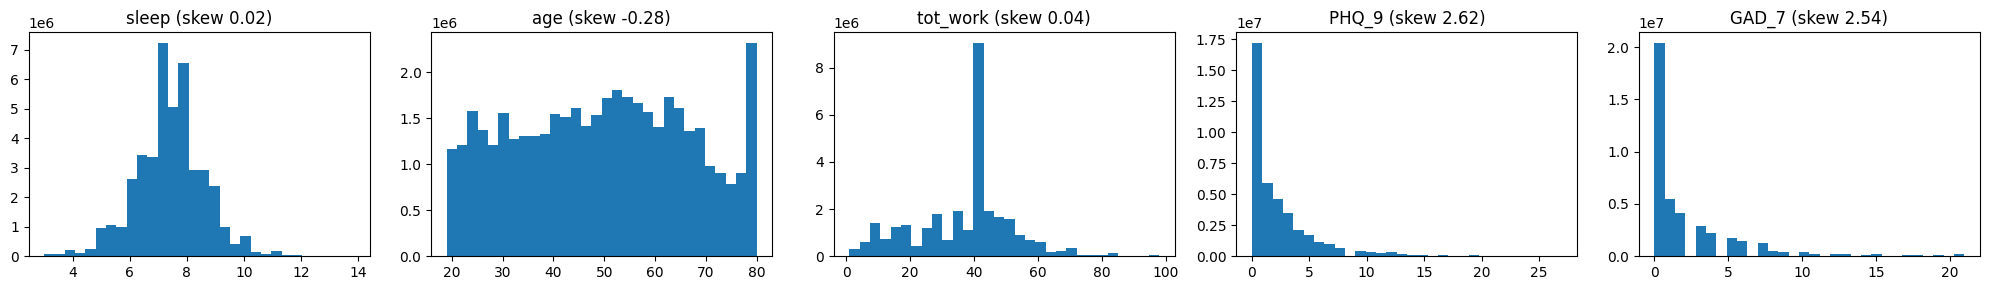

            왜도      선택
sleep     0.02    mean
age      -0.28    mean
tot_work  0.04    mean
PHQ_9     2.62  median
GAD_7     2.54  median


In [8]:
# 4-3. 연속형 요약통계 선택: 히스토그램과 왜도 (|왜도| >= 1 이면 중앙값(IQR), 아니면 평균(SE))
cont_keys = [(k, lab) for k, lab, c, typ, na, miss in [OUTCOME] + SPEC if typ == 'cont']
METHOD, SKEW = {}, {}
fig, axes = plt.subplots(1, len(cont_keys), figsize=(4 * len(cont_keys), 3))
for ax, (k, lab) in zip(axes, cont_keys):
    xv = X[k][final].dropna()
    SKEW[k] = float(xv.skew())
    METHOD[k] = 'median' if abs(SKEW[k]) >= 1 else 'mean'
    ax.hist(xv, bins=30, weights=wt[(final & X[k].notna()).values]); ax.set_title(f'{k} (skew {SKEW[k]:.2f})')
plt.tight_layout(); plt.show()
print(pd.DataFrame({'왜도': SKEW, '선택': METHOD}).round(2))


In [9]:
# 4-4. 가중 Table 1
def table(weighted=True):
    rows, stats = [], {}
    for key, lab, col, typ, na, miss in [OUTCOME] + SPEC:
        x = X[key]
        if typ == 'cat':
            cats = sorted([c for c in x[final].dropna().unique() if c != '비해당'], key=float)
            if (x[final] == '비해당').any(): cats.append('비해당')
            for c in cats + ['결측']:
                ind = x.isna() if c == '결측' else (x == c)
                row = {'변수': lab, '구분': code_label(key, c)}
                for g, m in M.items():
                    n = int((ind & m).sum())
                    p = w_prop(ind, m) * 100 if weighted else n / m.sum() * 100
                    row[HEAD[g]] = f'{n:,} ({p:.1f})'
                    if g == '전체': stats[(key, c)] = p
                rows.append(row)
        else:
            meth = METHOD[key]
            row = {'변수': lab, '구분': '가중 평균 (SE)' if (weighted and meth == 'mean') else
                                        '가중 중앙값 (IQR)' if weighted else
                                        '평균 (SD)' if meth == 'mean' else '중앙값 (IQR)'}
            miss_row = {'변수': lab, '구분': '결측 n'}
            for g, m in M.items():
                xm = x[m].dropna()
                if weighted and meth == 'mean':
                    mu, se = w_mean(x, m); txt = f'{mu:.2f} ({se:.2f})'
                elif weighted:
                    q = w_quant(x, m, (0.5, 0.25, 0.75)); txt = f'{q[0]:.1f} ({q[1]:.1f}-{q[2]:.1f})'
                elif meth == 'mean':
                    txt = f'{xm.mean():.2f} ({xm.std():.2f})'
                else:
                    q = xm.quantile([0.5, 0.25, 0.75]).values; txt = f'{q[0]:.1f} ({q[1]:.1f}-{q[2]:.1f})'
                row[HEAD[g]] = txt
                miss_row[HEAD[g]] = f'{int((x.isna() & m).sum()):,}'
                if g == '전체':
                    xa = x[M['전체']].dropna()
                    stats[(key, 'w')] = w_mean(x, m)[0]
                    stats[(key, 'u')] = xa.mean()
                    stats[(key, 'sd')] = xa.std()
            rows += [row, miss_row]
    return pd.DataFrame(rows), stats

tbl_w, st_w = table(weighted=True)
print(tbl_w.to_string(index=False))


                    변수           구분  전체 (n=5,800) 노출군 (n=1,422) 비교군 (n=4,378)
        하루 평균 수면시간(시간)   가중 평균 (SE)   7.43 (0.02)   7.32 (0.04)   7.46 (0.02)
        하루 평균 수면시간(시간)         결측 n             0             0             0
                 연령(세)   가중 평균 (SE)  49.61 (0.47)  45.08 (0.50)  51.20 (0.52)
                 연령(세)         결측 n             0             0             0
                    성별         코드 1  2,490 (50.0)    543 (45.0)  1,947 (51.8)
                    성별         코드 2  3,310 (50.0)    879 (55.0)  2,431 (48.2)
                    성별           결측       0 (0.0)       0 (0.0)       0 (0.0)
                 결혼 여부         코드 1  4,681 (74.9)  1,063 (70.1)  3,618 (76.6)
                 결혼 여부         코드 2  1,119 (25.1)    359 (29.9)    760 (23.4)
                 결혼 여부           결측       0 (0.0)       0 (0.0)       0 (0.0)
               소득 4분위수         코드 1  1,406 (23.9)    392 (27.2)  1,014 (22.8)
               소득 4분위수         코드 2  1,442 (24.8)    354 (25.0) 

In [10]:
# 4-5. 점검: 범주형 가중 %의 합이 100%인지 (결측·비해당 포함)
for key, lab, col, typ, na, miss in [OUTCOME] + SPEC:
    if typ != 'cat': continue
    sub = tbl_w[tbl_w['변수'] == lab]
    sums = [sum(float(s.split('(')[1].rstrip(')')) for s in sub[HEAD[g]]) for g in M]
    print(f'{lab}: 열별 % 합계 = {[round(s, 1) for s in sums]}')

# 4-6. 결측이 10%를 넘는 변수: 결측자와 응답자의 특성 비교 (연령 가중 평균, 여성 가중 %)
print()
for key, lab, col, typ, na, miss in [OUTCOME] + SPEC:
    x = X[key]; m = M['전체']
    share = (x.isna() & m).sum() / m.sum()
    if share > 0.10:
        miss_m, resp_m = m & x.isna(), m & x.notna()
        a1, a2 = w_mean(df['age'].astype(float), miss_m)[0], w_mean(df['age'].astype(float), resp_m)[0]
        f1 = w_prop(df['sex'] == 2, miss_m) * 100; f2 = w_prop(df['sex'] == 2, resp_m) * 100
        print(f'{lab}: 결측 {share*100:.1f}% | 연령 결측자 {a1:.1f} vs 응답자 {a2:.1f} | 여성 % 결측자 {f1:.1f} vs 응답자 {f2:.1f}')

# 4-7. 근로시간의 결측 내역 (비해당·무응답 구분, 각주 d용)
mm = M['전체']
print('\nEC_wht_23 (분석 대상): 888(비해당)', int((df['EC_wht_23'][mm] == 888).sum()),
      '| 999(무응답)', int((df['EC_wht_23'][mm] == 999).sum()), '| 원래 결측', int(df['EC_wht_23'][mm].isna().sum()))


성별: 열별 % 합계 = [100.0, 100.0, 100.0]
결혼 여부: 열별 % 합계 = [100.0, 100.0, 100.0]
소득 4분위수: 열별 % 합계 = [100.0, 100.0, 100.0]
교육수준: 열별 % 합계 = [100.0, 100.0, 100.0]
경제활동 상태 (EC1_1): 열별 % 합계 = [100.0, 100.0, 99.9]
근로형태 (EC_wht_5): 열별 % 합계 = [100.0, 100.0, 100.0]
고혈압 의사진단 (DI1_dg): 열별 % 합계 = [100.0, 100.0, 100.0]
현재 흡연 (sm_presnt): 열별 % 합계 = [100.0, 100.0, 100.0]
1년간 음주빈도 (BD1_11): 열별 % 합계 = [100.0, 100.0, 100.0]
유산소 신체활동 (pa_aerobic): 열별 % 합계 = [100.0, 100.0, 99.9]

주당 평균 근로시간 (EC_wht_23): 결측 34.2% | 연령 결측자 56.8 vs 응답자 46.6 | 여성 % 결측자 63.1 vs 응답자 44.6

EC_wht_23 (분석 대상): 888(비해당) 1593 | 999(무응답) 389 | 원래 결측 0


## 5. 같은 형식의 비가중 표와 차이 (B-3)


In [11]:
tbl_u, st_u = table(weighted=False)
print(tbl_u.to_string(index=False))

# 차이 계산: 범주형은 %p, 연속형은 표준화 차이(가중 평균 - 비가중 평균) / 비가중 SD
recs = []
for key, lab, col, typ, na, miss in [OUTCOME] + SPEC:
    if typ == 'cat':
        for (k, c), pw in st_w.items():
            if k == key and c != '결측':
                recs.append([lab, code_label(key, c), pw, st_u[(k, c)], pw - st_u[(k, c)], abs(pw - st_u[(k, c)]), '%p'])
    else:
        sd = st_w[(key, 'sd')]
        smd = (st_w[(key, 'w')] - st_w[(key, 'u')]) / sd
        recs.append([lab, '평균', st_w[(key, 'w')], st_w[(key, 'u')], smd, abs(smd) * 100, '표준화 차이'])
cmp_df = pd.DataFrame(recs, columns=['변수', '구분', '가중', '비가중', '차이', '순위점수', '기준'])
best = cmp_df.sort_values('순위점수', ascending=False).drop_duplicates('변수').head(3)
print()
print(best[['변수', '구분', '가중', '비가중', '차이', '기준']].round(3).to_string(index=False))


                    변수        구분  전체 (n=5,800) 노출군 (n=1,422) 비교군 (n=4,378)
        하루 평균 수면시간(시간)   평균 (SD)   7.42 (1.24)   7.31 (1.32)   7.46 (1.21)
        하루 평균 수면시간(시간)      결측 n             0             0             0
                 연령(세)   평균 (SD) 53.79 (17.06) 48.49 (16.11) 55.51 (17.01)
                 연령(세)      결측 n             0             0             0
                    성별      코드 1  2,490 (42.9)    543 (38.2)  1,947 (44.5)
                    성별      코드 2  3,310 (57.1)    879 (61.8)  2,431 (55.5)
                    성별        결측       0 (0.0)       0 (0.0)       0 (0.0)
                 결혼 여부      코드 1  4,681 (80.7)  1,063 (74.8)  3,618 (82.6)
                 결혼 여부      코드 2  1,119 (19.3)    359 (25.2)    760 (17.4)
                 결혼 여부        결측       0 (0.0)       0 (0.0)       0 (0.0)
               소득 4분위수      코드 1  1,406 (24.2)    392 (27.6)  1,014 (23.2)
               소득 4분위수      코드 2  1,442 (24.9)    354 (24.9)  1,088 (24.9)
               소득 4분위수   

In [12]:
# 결과 파일 만들기: 표와 각주를 마크다운으로 저장 (docs/10_table1.md에 붙여 넣기)
def to_md(d):
    d = d.copy()
    if d.columns[0] == '변수':
        d.loc[d['변수'].duplicated(), '변수'] = ''
    head = '| ' + ' | '.join(d.columns) + ' |'
    sep = '|' + '|'.join(['---'] * len(d.columns)) + '|'
    body = ['| ' + ' | '.join(map(str, r)) + ' |' for r in d.values]
    return '\n'.join([head, sep, *body])

flow_fmt = flow.copy()
flow_fmt['남은 인원'] = flow_fmt['남은 인원'].map(lambda v: f'{int(v):,}')
flow_fmt['빠진 인원'] = flow_fmt['빠진 인원'].map(lambda v: '' if pd.isna(v) else f'{int(v):,}')
mean_vars = [lab for k, lab in cont_keys if METHOD[k] == 'mean']
med_vars  = [lab for k, lab in cont_keys if METHOD[k] == 'median']
foot_b = '연속형 변수는 히스토그램과 왜도(|왜도| >= 1이면 중앙값)로 요약통계를 골랐다. ' + \
         '왜도: ' + ', '.join(f'{lab} {SKEW[k]:.2f}' for k, lab in cont_keys) + '. ' + \
         f"가중 평균(SE): {', '.join(mean_vars) or '없음'}. 가중 중앙값(IQR): {', '.join(med_vars) or '없음'}."

mermaid = f'''```mermaid
flowchart TD
    A["조사 참여자 전체<br/>n = {n0:,}"] --> B["만 19세 이상<br/>n = {n1:,}"]
    A -.-> X1["제외: 만 19세 미만<br/>n = {n0-n1:,}"]
    B --> C["노출(mh_stress) 정의 가능<br/>n = {n2:,}"]
    B -.-> X2["제외: 노출 무응답·비해당<br/>n = {n1-n2:,}"]
    C --> D["최종 분석 대상<br/>n = {n4:,}"]
    C -.-> X3["제외: 결과 없음 {n2-n3:,} + 이상값 {n3-n4:,}<br/>n = {n2-n4:,}"]
    D --> E["노출군(스트레스 인지)<br/>n = {n_exp:,}"]
    D --> F["비교군<br/>n = {n_cmp:,}"]
```'''

out = '\n\n'.join([
    '## 자동 생성 결과 (노트북 출력)', '### B-1 흐름도 (Mermaid)', mermaid,
    '### B-1 단계표', to_md(flow_fmt),
    '### B-2 Table 1 (가중)', to_md(tbl_w), '각주 b 문장', foot_b,
    '### B-3 비가중 표', to_md(tbl_u),
    '### B-3 가중 대 비가중 차이 (전체 열 기준)', to_md(cmp_df.round(3).astype(str)),
    '### B-3 차이가 큰 변수 3개', to_md(best[['변수', '구분', '가중', '비가중', '차이', '기준']].round(3).astype(str)),
])
with open('table1_tables.md', 'w', encoding='utf-8') as f:
    f.write(out)
print(out)


## 자동 생성 결과 (노트북 출력)

### B-1 흐름도 (Mermaid)

```mermaid
flowchart TD
    A["조사 참여자 전체<br/>n = 6,997"] --> B["만 19세 이상<br/>n = 6,033"]
    A -.-> X1["제외: 만 19세 미만<br/>n = 964"]
    B --> C["노출(mh_stress) 정의 가능<br/>n = 5,813"]
    B -.-> X2["제외: 노출 무응답·비해당<br/>n = 220"]
    C --> D["최종 분석 대상<br/>n = 5,800"]
    C -.-> X3["제외: 결과 없음 8 + 이상값 5<br/>n = 13"]
    D --> E["노출군(스트레스 인지)<br/>n = 1,422"]
    D --> F["비교군<br/>n = 4,378"]
```

### B-1 단계표

| 단계 | 기준 | 남은 인원 | 빠진 인원 | 빠진 이유 |
|---|---|---|---|---|
| 1 | 조사 참여자 전체 | 6,997 |  |  |
| 2 | 만 19세 이상 | 6,033 | 964 | 설계상 제외 (만 19세 미만) |
| 3 | 노출(mh_stress) 정의 가능 | 5,813 | 220 | BP1 특수코드 8, 9 및 결측 |
| 4 | 결과(수면시간) 산출 가능 | 5,805 | 8 | 수면 시각 변수의 88, 99 및 결측 |
| 5 | 수면시간 이상값 제외 (3시간 미만, 16시간 초과) | 5,800 | 5 | 이상값 |

### B-2 Table 1 (가중)

| 변수 | 구분 | 전체 (n=5,800) | 노출군 (n=1,422) | 비교군 (n=4,378) |
|---|---|---|---|---|
| 하루 평균 수면시간(시간) | 가중 평균 (SE) | 7.43 (0.02) | 7.32 (0.04) | 7.46 (0.02) |
|  | 결측 n | 0 | 0 | 0 |
| 연령(세) | 가중 평균 (SE) | 49.61 (0